# Ciclo diário médio: SONDA (10 min) e NASA POWER (1 h), em gráficos separados

**Para que serve:** mostrar como temperatura, umidade, onda curta e onda longa se comportam, em média, ao
longo das 24 horas do dia, e **quando** acontecem o máximo e o mínimo. Só mostra, não altera nada.

**O que é o ciclo diário médio:** para cada horário do dia, a média de todos os dias do período (por
exemplo, a média de todas as 14:45). A faixa sombreada vai do percentil 25 ao 75: metade dos dias fica
dentro dela.

**Entradas:**
- SONDA: séries prontas de **10 min** (`sonda_tp_sfc_10min`, `sonda_humid_10min`, `sonda_glo_10min`,
  `sonda_lw_calc_10min`);
- NASA POWER: o CSV horário **original** (1 h é a menor resolução que o NASA POWER oferece).

## Onde fica cada ponto: início, meio ou fim do intervalo

Cada valor é a **média de um intervalo**, e não uma medida num instante. O horário escrito no arquivo é
só um rótulo para esse intervalo, e cada fonte rotula de um jeito:

```text
                14:00 ─────────────────────────── 15:00
NASA POWER:     HR = 14  (rótulo no INÍCIO da hora)
SONDA 10 min:                                14:40 ── 14:50   rótulo 14:50 (FIM dos 10 min)
```

Para as duas fontes seguirem **a mesma regra**, cada ponto vai para o **meio** do seu intervalo:

| Fonte | Rótulo no arquivo | Ajuste | Ponto no gráfico |
|---|---|---|---|
| SONDA (10 min) | fim do intervalo (14:50 = média de 14:40–14:50) | −5 min | 14:45 |
| NASA POWER (1 h) | início da hora (HR = 14 = média de 14:00–15:00) | +30 min | 14:30 |

Essas duas linhas (passo 1) são as **únicas** que tratam de onde cada arquivo marca o horário. Depois
delas, as duas fontes seguem a mesma regra. Os passos seguintes são iguais para as duas: período comum,
hora local (UTC−3) e ciclo diário.

**Figuras antigas da SONDA** (`resultados/ciclo_diario/sonda/`): rotulam pelo fim do intervalo, então lá
os extremos aparecem 5 min (10 min) ou 30 min (1 h) mais tarde, **com os mesmos valores**.

**Cuidados na leitura:**
- **Onda longa:** nas duas fontes é a radiação **incidente**, a que **desce** da atmosfera para o chão
  (no NASA POWER, `ALLSKY_SFC_LW_DWN`, *downward*). Ela depende da temperatura e da umidade do ar, e
  por isso o esperado é o pico perto da hora mais quente da tarde. O pico às ~20 h e o mínimo às ~11 h
  da SONDA **não são físicos**: há suspeita de erro ligado ao sol no pirgeômetro ou no cálculo (causa não
  confirmada).
- **Umidade da SONDA:** as falhas de mar–mai/2025 foram preenchidas com 100 % (decisão provisória).
- **Período:** em cada variável, as duas fontes usam **o mesmo período** (o trecho em que as duas têm
  dado). A onda curta da SONDA só começa em 08/02/2024, então o NASA POWER também começa aí.
- **NASA POWER** é a média de uma célula de grade (~55–110 km), não uma medida no ponto da estação.

## 1. Configuração e leitura

In [1]:
%matplotlib inline
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RAIZ = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "config").is_dir())
sys.path.insert(0, str(RAIZ))

from config.caminhos_e_parametros import DPI_FIGURAS, PASTA_NASA_POWER, PASTA_RESULTADOS
from src.dados.nasa_power import carregar_nasa_power
from src.wavelet import motor

# ----------------------------- CONFIGURAÇÃO -----------------------------
VARIAVEIS = {  # titulo: nome na SONDA, nome no NASA POWER, unidade
    "Temperatura do ar": {"sonda": "tp_sfc", "power": "T2M", "unidade": "°C"},
    "Umidade relativa": {"sonda": "humid", "power": "RH2M", "unidade": "%"},
    "Radiação de onda curta": {"sonda": "glo", "power": "ALLSKY_SFC_SW_DWN", "unidade": "W/m²"},
    "Radiação de onda longa": {"sonda": "lw_calc", "power": "ALLSKY_SFC_LW_DWN", "unidade": "W/m²"},
}
ANOTAR_MINIMO = {"Radiação de onda curta": False}  # o minimo da onda curta e a noite (~0)
FAIXA = (0.25, 0.75)             # percentis da faixa sombreada (None para nao desenhar)
FUSO_LOCAL = pd.Timedelta(hours=-3)
SALVAR = True
PASTA_SAIDA = PASTA_RESULTADOS / "ciclo_diario"
ARQUIVO_NASA = sorted(PASTA_NASA_POWER.glob("POWER_Point_Hourly_*.csv"))[-1]
# ------------------------------------------------------------------------

FONTES = {
    "SONDA": {"passo": pd.Timedelta(minutes=10), "cor": "#2a78d6"},
    "NASA POWER": {"passo": pd.Timedelta(hours=1), "cor": "#eb6834"},
}
COR_TEXTO = "#222222"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

dados_power, _ = carregar_nasa_power(ARQUIVO_NASA)

## 2. Os passos: meio do intervalo, mesmo período e hora local

Para cada variável:
1. **meio do intervalo:** SONDA −5 min, NASA POWER +30 min;
2. **mesmo período:** corta as duas no trecho em que as duas têm dado (ainda em UTC);
3. **hora local:** −3 h nas duas.

In [2]:
series = {}
linhas_periodo = []
for titulo, info in VARIAVEIS.items():
    sonda = motor.carregar_serie_pronta(f"sonda_{info['sonda']}_10min")
    power = dados_power[info["power"]].copy()

    # Passo 1: cada fonte no meio do intervalo da media
    sonda.index = sonda.index - pd.Timedelta(minutes=5)    # fim dos 10 min -> meio
    power.index = power.index + pd.Timedelta(minutes=30)   # inicio da hora -> meio

    # Passo 1b: mesmo periodo nas duas fontes
    inicio = max(sonda.index[0], power.index[0])
    fim = min(sonda.index[-1], power.index[-1])
    sonda, power = sonda.loc[inicio:fim], power.loc[inicio:fim]

    # Passo 2: hora local
    sonda.index = sonda.index + FUSO_LOCAL
    power.index = power.index + FUSO_LOCAL

    series[titulo] = {"SONDA": sonda, "NASA POWER": power}
    for fonte, serie in series[titulo].items():
        linhas_periodo.append({"variavel": titulo, "fonte": fonte,
                               "inicio (hora local)": serie.index[0], "fim (hora local)": serie.index[-1],
                               "valores": len(serie), "dias": serie.index.normalize().nunique()})

periodos = pd.DataFrame(linhas_periodo)
display(periodos)

,variavel,fonte,inicio (hora local),fim (hora local),valores,dias
0,Temperatura do ar,SONDA,2023-11-30 21:35:00,2026-06-30 20:25:00,135786,944
1,Temperatura do ar,NASA POWER,2023-11-30 21:30:00,2026-06-30 20:30:00,22632,944
2,Umidade relativa,SONDA,2023-11-30 21:35:00,2026-06-30 20:25:00,135786,944
3,Umidade relativa,NASA POWER,2023-11-30 21:30:00,2026-06-30 20:30:00,22632,944
4,Radiação de onda curta,SONDA,2024-02-07 20:55:00,2026-06-30 20:25:00,125854,875
5,Radiação de onda curta,NASA POWER,2024-02-07 21:30:00,2026-06-30 20:30:00,20976,875
6,Radiação de onda longa,SONDA,2023-11-30 21:35:00,2026-06-30 20:25:00,135786,944
7,Radiação de onda longa,NASA POWER,2023-11-30 21:30:00,2026-06-30 20:30:00,22632,944


## 3. Ciclo diário (a mesma função para as duas fontes)

A posição de cada valor no dia é `hora + minuto/60`. Na SONDA, isso dá 144 posições (0,08 · 0,25 · … ·
23,92); no NASA POWER, 24 (0,5 · 1,5 · … · 23,5).

`descrever_horario` faz o caminho de volta: da posição para o horário e o intervalo da média. Por
exemplo, 14,75 na SONDA vira "14:45 (média de 14:40–14:50)", e 14,5 no NASA POWER vira "14:30 (média de
14:00–15:00)".

In [3]:
def ciclo_diario(serie):
    pos = serie.index.hour + serie.index.minute / 60
    por_posicao = serie.groupby(pos)
    ciclo = pd.DataFrame({"media": por_posicao.mean()})
    if FAIXA is not None:
        ciclo["baixo"] = por_posicao.quantile(FAIXA[0])
        ciclo["alto"] = por_posicao.quantile(FAIXA[1])
    return ciclo


def formatar_hora(minutos):
    minutos = int(round(minutos))
    return "24:00" if minutos == 1440 else f"{(minutos // 60) % 24:02d}:{minutos % 60:02d}"


def descrever_horario(pos, passo):
    centro = pos * 60
    meio_passo = passo.total_seconds() / 60 / 2
    horario = formatar_hora(centro)
    intervalo = f"média de {formatar_hora(centro - meio_passo)}–{formatar_hora(centro + meio_passo)}"
    return horario, intervalo


def numero(valor):
    return f"{valor:.1f}".replace(".", ",")


ciclos = {titulo: {fonte: ciclo_diario(serie) for fonte, serie in por_fonte.items()}
          for titulo, por_fonte in series.items()}
for titulo, por_fonte in ciclos.items():
    print(titulo, {fonte: len(ciclo) for fonte, ciclo in por_fonte.items()}, "posicoes")

Temperatura do ar {'SONDA': 144, 'NASA POWER': 24} posicoes
Umidade relativa {'SONDA': 144, 'NASA POWER': 24} posicoes
Radiação de onda curta {'SONDA': 144, 'NASA POWER': 24} posicoes
Radiação de onda longa {'SONDA': 144, 'NASA POWER': 24} posicoes


## 4. Máximos e mínimos

Para cada variável e fonte: o horário (meio do intervalo), o intervalo da média e o valor do máximo e do
mínimo do ciclo diário médio.

In [4]:
linhas = []
for titulo, por_fonte in ciclos.items():
    for fonte, ciclo in por_fonte.items():
        passo = FONTES[fonte]["passo"]
        pos_max, pos_min = ciclo["media"].idxmax(), ciclo["media"].idxmin()
        hora_max, intervalo_max = descrever_horario(pos_max, passo)
        hora_min, intervalo_min = descrever_horario(pos_min, passo)
        linhas.append({
            "variavel": titulo, "fonte": fonte, "passo": "10 min" if passo.seconds == 600 else "1 h",
            "hora do máximo": hora_max, "intervalo do máximo": intervalo_max,
            "máximo": round(ciclo["media"].max(), 1),
            "hora do mínimo": hora_min, "intervalo do mínimo": intervalo_min,
            "mínimo": round(ciclo["media"].min(), 1),
            "amplitude": round(ciclo["media"].max() - ciclo["media"].min(), 1),
            "unidade": VARIAVEIS[titulo]["unidade"],
        })
extremos = pd.DataFrame(linhas)
display(extremos)

,variavel,fonte,passo,hora do máximo,intervalo do máximo,máximo,hora do mínimo,intervalo do mínimo,mínimo,amplitude,unidade
0,Temperatura do ar,SONDA,10 min,14:25,média de 14:20–14:30,26.5,05:35,média de 05:30–05:40,16.9,9.6,°C
1,Temperatura do ar,NASA POWER,1 h,13:30,média de 13:00–14:00,27.9,05:30,média de 05:00–06:00,14.7,13.1,°C
2,Umidade relativa,SONDA,10 min,05:35,média de 05:30–05:40,93.9,14:35,média de 14:30–14:40,52.1,41.8,%
3,Umidade relativa,NASA POWER,1 h,05:30,média de 05:00–06:00,94.7,13:30,média de 13:00–14:00,40.5,54.2,%
4,Radiação de onda curta,SONDA,10 min,11:55,média de 11:50–12:00,728.8,19:15,média de 19:10–19:20,-1.0,729.8,W/m²
5,Radiação de onda curta,NASA POWER,1 h,11:30,média de 11:00–12:00,699.0,00:30,média de 00:00–01:00,0.0,699.0,W/m²
6,Radiação de onda longa,SONDA,10 min,19:25,média de 19:20–19:30,367.3,10:15,média de 10:10–10:20,347.4,19.9,W/m²
7,Radiação de onda longa,NASA POWER,1 h,14:30,média de 14:00–15:00,392.7,04:30,média de 04:00–05:00,335.9,56.8,W/m²


## 5. Gráficos (um por fonte)

Uma figura para cada fonte, porque o passo de tempo é diferente (10 min e 1 h). As duas usam o mesmo eixo
de horário (0 a 24 h, hora local) e o mesmo período de cada variável. A SONDA tem 144 pontos por dia; o
NASA POWER tem 24, e por isso aparece com marcadores. Os marcadores grandes mostram o máximo e o
mínimo, e os valores estão escritos embaixo de cada painel.

In [5]:
def desenhar_fonte(fonte, nome_arquivo):
    cor, passo = FONTES[fonte]["cor"], FONTES[fonte]["passo"]
    rotulo_passo = "10 min" if passo == pd.Timedelta(minutes=10) else "1 h"
    fig, eixos = plt.subplots(2, 2, figsize=(14, 9.5))
    for eixo, (titulo, por_fonte) in zip(eixos.flat, ciclos.items()):
        ciclo, unidade = por_fonte[fonte], VARIAVEIS[titulo]["unidade"]
        if FAIXA is not None:
            eixo.fill_between(ciclo.index, ciclo["baixo"], ciclo["alto"], color=cor, alpha=0.15, lw=0)
        estilo = {"marker": "o", "ms": 3.5} if fonte == "NASA POWER" else {}
        eixo.plot(ciclo.index, ciclo["media"], color=cor, lw=2, **estilo)

        extremos_fonte = [("Máx", ciclo["media"].idxmax())]
        if ANOTAR_MINIMO.get(titulo, True):
            extremos_fonte.append(("Mín", ciclo["media"].idxmin()))
        textos = []
        for nome, pos in extremos_fonte:
            valor = ciclo.loc[pos, "media"]
            eixo.scatter(pos, valor, s=70, color=cor, edgecolor="white", linewidth=1.5, zorder=5)
            horario, intervalo = descrever_horario(pos, passo)
            textos.append(f"{nome} {horario} ({intervalo}): {numero(valor)} {unidade}")

        periodo = series[titulo][fonte].index
        eixo.set_title(f"{titulo}  ({periodo[0]:%d/%m/%Y} a {periodo[-1]:%d/%m/%Y})", loc="left", fontsize=11)
        eixo.set_xlim(0, 24)
        eixo.set_xticks(range(0, 25, 3), [f"{h:02d}h" for h in range(0, 25, 3)])
        eixo.set_xlabel("hora local (UTC−3)")
        eixo.set_ylabel(unidade)
        eixo.text(0, -0.2, "   |   ".join(textos), transform=eixo.transAxes, va="top", ha="left",
                  fontsize=9, color=COR_TEXTO)
    fig.suptitle(f"Ciclo diário médio - {fonte} ({rotulo_passo}) - Cachoeira Paulista", fontsize=13)
    fig.subplots_adjust(left=0.06, right=0.98, top=0.92, bottom=0.1, hspace=0.55, wspace=0.16)
    if SALVAR:
        PASTA_SAIDA.mkdir(parents=True, exist_ok=True)
        caminho = PASTA_SAIDA / nome_arquivo
        fig.savefig(caminho, dpi=DPI_FIGURAS, bbox_inches="tight")
        print("Salvo:", caminho)
    plt.show()

### 5.1 SONDA (10 min)

Salvo: C:\Users\sarah\OneDrive\Documentos\Sarah - FILES\Iniciação Cientifica - INPE\02_dados\resultados\ciclo_diario\ciclo_diario_sonda_10min.png


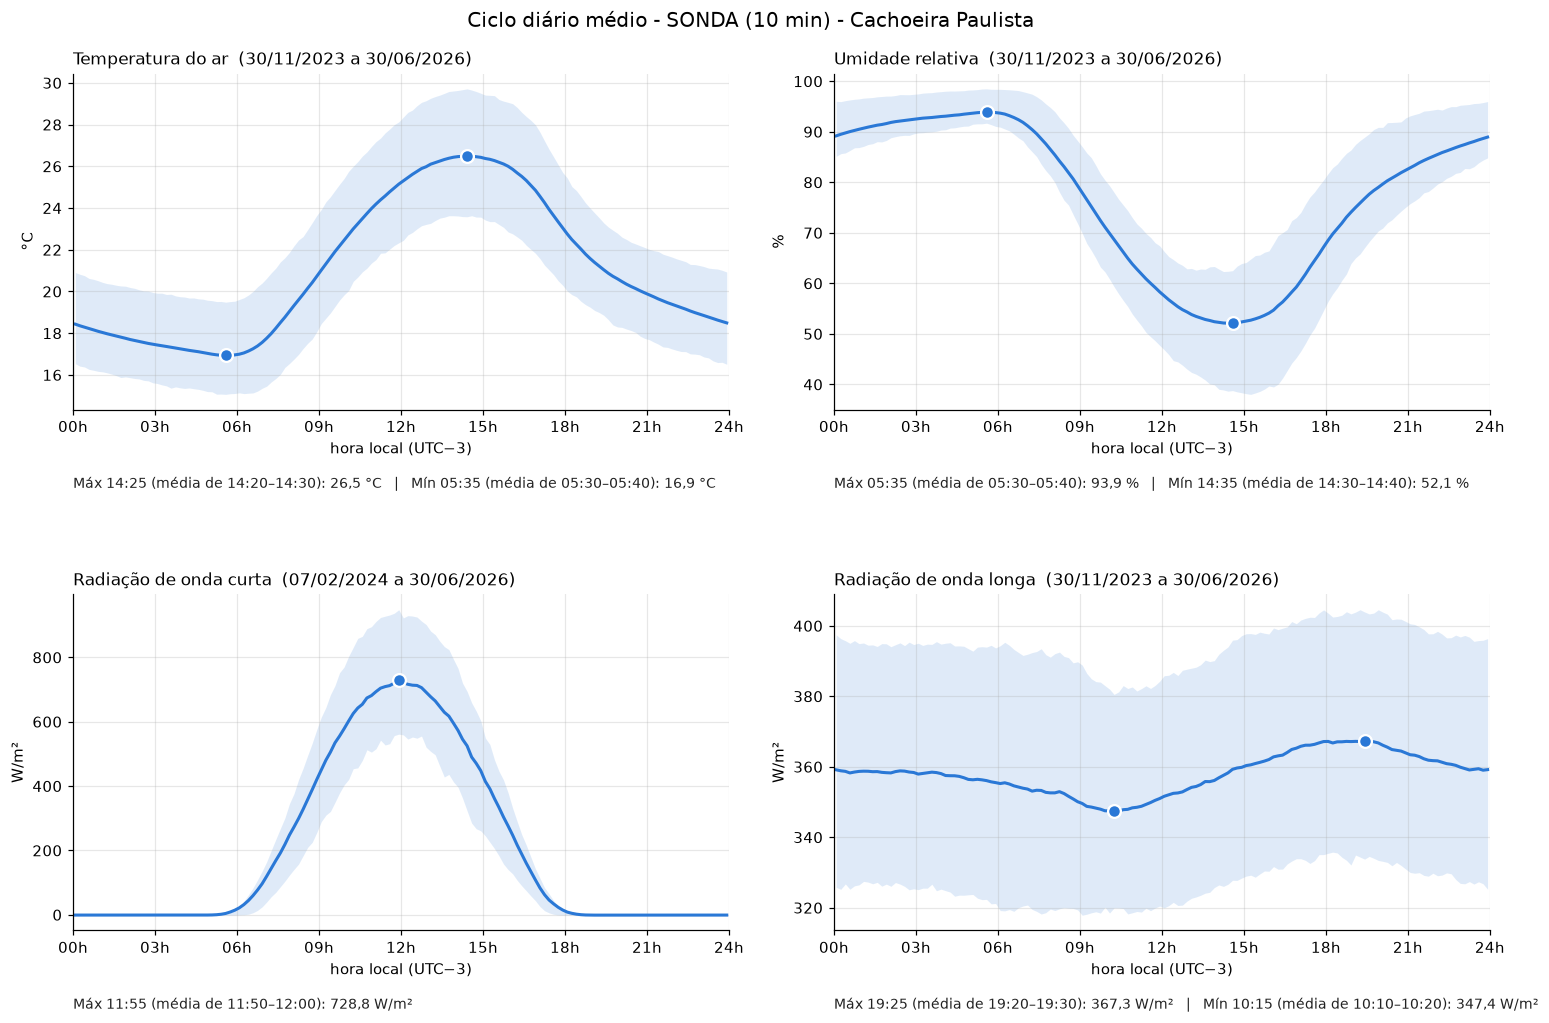

In [6]:
desenhar_fonte("SONDA", "ciclo_diario_sonda_10min.png")

### 5.2 NASA POWER (1 h)

Salvo: C:\Users\sarah\OneDrive\Documentos\Sarah - FILES\Iniciação Cientifica - INPE\02_dados\resultados\ciclo_diario\ciclo_diario_nasapower_1h.png


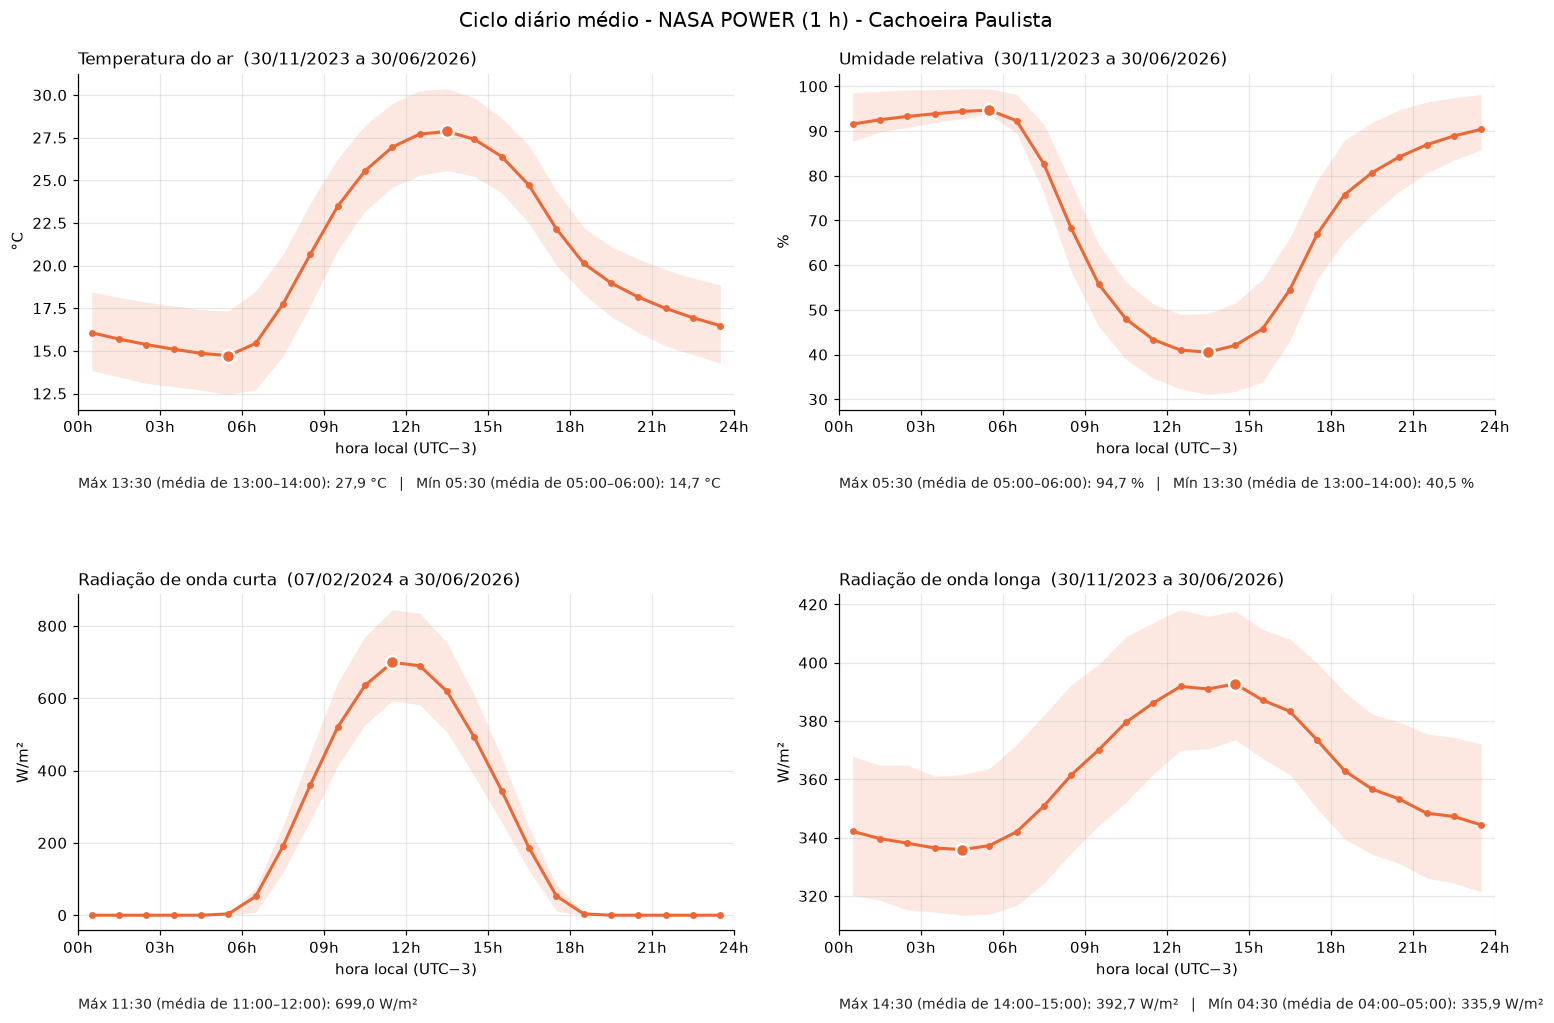

In [7]:
desenhar_fonte("NASA POWER", "ciclo_diario_nasapower_1h.png")

## 6. Exportação da tabela de extremos

In [8]:
if SALVAR:
    caminho = PASTA_SAIDA / "extremos_ciclo_diario.csv"
    extremos.to_csv(caminho, index=False, encoding="utf-8-sig")
    print("Salvo:", caminho)

Salvo: C:\Users\sarah\OneDrive\Documentos\Sarah - FILES\Iniciação Cientifica - INPE\02_dados\resultados\ciclo_diario\extremos_ciclo_diario.csv
